# WiPER Benchmarking — v7 (k-fold sulle identità + feature più ricche)

Notebook **autonomo**: legge direttamente le ampiezze prodotte da *WiPER-DataProcessing* (stessa cartella/sanitizzazione di DatasetGeneration v4) e costruisce da solo finestre e grafi. Non servono i `.pt` della v4.

**Perché la v7** (risultati v6: anche `same_*` arrivava solo a ~20% Rank-1, validazione con 6 identità = rumore, rete ≈ non addestrata, handcrafted+LDA migliore)

| # | v6 | v7 |
|---|---|---|
| 1 | 1 split 22/22 + validazione su 6 identità (chance Rank-1 val 16.7% vs 4.5% test: numeri non confrontabili) | **k-fold sulle identità** (`n_folds=4`: 33 identità di training, 11 di test per fold). Tutte le 44 identità vengono testate; **nessuna selezione di checkpoint** (budget di epoche fisso) -> nessuna fuga di informazione |
| 2 | Handcrafted: solo media / std / variazione media per sottoportante | Gruppi di feature: `static`, `dyn_std`, `diff`, **`spec`** (potenza a bande dell'attività e delle prime 3 PC), **`eig`** (spettro degli autovalori tra sottoportanti), **`pc1`** (carichi della prima PC) |
| 3 | Feature su finestre da 100 pacchetti | Confronto **finestre vs registrazione intera** (~180 pacchetti) |
| 4 | — | **Tabella di ablazione**: quale gruppo di feature porta informazione sull'identità |
| 5 | Chance solo per Rank-1 | Chance anche per **mAP** (formula esatta) |

Protocolli (per registrazione, come v6): `cross` (gallery=saluto, probe=tPose), `cross_rev`, `same_saluto`, `same_tpose` (leave-one-recording-out).

> Con `n_folds=4` il gallery di ogni fold ha 11 identità: la chance è più alta (Rank-1 ~9%) che con 22 identità. Confronta sempre con la riga *Chance*.

## 1. Imports e configurazione

In [1]:
import os, re, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import display

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    # --- dati (devono coincidere con DatasetGeneration v4) ---
    output_folder='./output/',
    sanitization='zscore',            # 'raw' | 'hampel' | 'zscore' | 'iqr'
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52, n_packets=100, stride=25,
    fs_hz=None,                       # frequenza di pacchetto (Hz) se la conosci: serve solo a stampare le bande in Hz
    # --- cross-validation ---
    n_folds=4,                        # 4 -> 33 train / 11 test ; 2 -> 22/22 (come v6) ; 11 -> 40/4
    # --- feature ---
    n_bands=8, n_pcs=3, n_eig=8,
    # --- rete neurale ---
    run_neural=True,
    n_epochs=40, batches_per_epoch=20, P=8, K=4,
    lr=3e-4, weight_decay=5e-4, grad_clip=1.0,
    norm_mode='scale',                # 'none' | 'scale' | 'graph'
    temporal_dim=64, hidden=64, heads=4, gat_out=128, emb_dim=128, dropout=0.2, band_k=4,
    margin=0.3, ce_weight=1.0, label_smoothing=0.1, lambda_gc=0.005,
    augment=True,
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
input_directory = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| input:', input_directory)

device: cpu | input: ./output/CSV/sanitized_amplitudes/zscore_amplitudes


## 2. Caricamento delle registrazioni e fold sulle identità

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(input_directory), f'Cartella non trovata: {input_directory}'

recs = []
for fname in sorted(os.listdir(input_directory)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']: continue
    m = KEY_RE.match(key)
    if not m: print('ignorato (nome non riconosciuto):', key); continue
    arr = pd.read_csv(os.path.join(input_directory, fname)).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float32)
    assert arr.shape[1] == CFG['n_subcarriers'], f'{fname}: {arr.shape[1]} sottoportanti'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key, data=arr))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
lens = np.array([r['data'].shape[0] for r in recs])
print(f'{R} registrazioni | {len(set(rec_sid))} identità | azioni: {sorted(set(map(str, rec_act)))}')
print(f'pacchetti per registrazione: min {lens.min()}  mediana {int(np.median(lens))}  max {lens.max()}')
if CFG['fs_hz']:
    print(f"durata mediana: {np.median(lens) / CFG['fs_hz']:.1f} s | finestra {CFG['n_packets'] / CFG['fs_hz']:.2f} s")
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [set(all_ids[i] for i in chunk) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = []
for f, test_set in enumerate(fold_ids):
    test_idx = np.where(np.isin(rec_sid, list(test_set)))[0]
    train_idx = np.where(~np.isin(rec_sid, list(test_set)))[0]
    folds.append((train_idx, test_idx))
print('Fold:', [(len(s), len(tr) // 10) for s, (tr, _) in zip(fold_ids, folds)], '(identità di test, identità di training)')

440 registrazioni | 44 identità | azioni: ['saluto', 'tpose']
pacchetti per registrazione: min 100  mediana 179  max 191
Fold: [(11, 33), (11, 33), (11, 33), (11, 33)] (identità di test, identità di training)


## 3. Feature handcrafted (gruppi)

In [3]:
def band_power(sig, n_bands):
    # potenza relativa in n_bands bande lineari di frequenza normalizzata + log della potenza totale
    s = sig - sig.mean()
    spec = np.abs(np.fft.rfft(s * np.hanning(len(s)))) ** 2
    spec = spec[1:]                                              # via la componente continua
    edges = np.linspace(0, len(spec), n_bands + 1).astype(int)
    bp = np.array([spec[a:b].sum() for a, b in zip(edges[:-1], edges[1:])]) + 1e-12
    tot = bp.sum()
    return np.concatenate([np.log(bp / tot), [np.log(tot)]])

def feature_groups(arr):
    # arr: [T, 52] ampiezze. Restituisce dict gruppo -> vettore
    X = arr / (arr.mean() + 1e-8)                                # via il guadagno globale
    T = X.shape[0]
    Xc = X - X.mean(axis=0, keepdims=True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    ev = S ** 2 / (S ** 2).sum()
    n_pc = CFG['n_pcs']
    pcs = U[:, :n_pc] * S[:n_pc]                                 # serie temporali delle prime PC
    v1 = Vt[0] if Vt[0].sum() >= 0 else -Vt[0]                   # segno fissato
    spec = [band_power(X.mean(axis=1), CFG['n_bands'])] + [band_power(pcs[:, k], CFG['n_bands']) for k in range(n_pc)]
    return {
        'static':  X.mean(axis=0),
        'dyn_std': X.std(axis=0),
        'diff':    np.abs(np.diff(X, axis=0)).mean(axis=0),
        'spec':    np.concatenate(spec),
        'eig':     np.concatenate([ev[:CFG['n_eig']], [np.log(S[0] / (S[1] + 1e-8))]]),
        'pc1':     v1,
    }

GROUPS = ['static', 'dyn_std', 'diff', 'spec', 'eig', 'pc1']

def sliding_windows(arr, n, stride):
    return [arr[s:s + n] for s in range(0, arr.shape[0] - n + 1, stride)]

t0 = time.time()
feat_whole = defaultdict(list); feat_win = defaultdict(list)
for r in recs:
    g = feature_groups(r['data'])                                              # registrazione intera
    for k in GROUPS: feat_whole[k].append(g[k])
    wl = [feature_groups(w) for w in sliding_windows(r['data'], CFG['n_packets'], CFG['stride'])]   # media sulle finestre
    for k in GROUPS: feat_win[k].append(np.mean([w[k] for w in wl], axis=0))
feat_whole = {k: np.stack(v) for k, v in feat_whole.items()}
feat_win   = {k: np.stack(v) for k, v in feat_win.items()}
print(f'feature calcolate in {time.time() - t0:.1f}s |', {k: feat_whole[k].shape[1] for k in GROUPS})

feature calcolate in 5.6s | {'static': 52, 'dyn_std': 52, 'diff': 52, 'spec': 36, 'eig': 9, 'pc1': 52}


## 4. Metriche e protocolli

In [4]:
def expected_ap_random(n, p):
    # mAP atteso con ranking casuale: n elementi in gallery, p positivi
    if n <= 1: return 1.0
    i = np.arange(1, n + 1)
    return float(np.sum((1.0 / i) * (1 + (i - 1) * (p - 1) / (n - 1))) / n)

def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False, K=10):
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf); np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=np.nan, rank5=np.nan, mAP=np.nan, n_queries=0, chance_rank1=np.nan, chance_mAP=np.nan)
    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    ap = ((cum / (np.arange(m.shape[1]) + 1)) * m).sum(axis=1) / m.sum(axis=1)
    n_gal = matches.shape[1] - (1 if exclude_self else 0)
    pos = matches.sum(1)
    return dict(rank1=cmc[0], rank5=cmc[min(4, len(cmc) - 1)], mAP=ap.mean() * 100.0, n_queries=len(sim),
                chance_rank1=(pos / n_gal).mean() * 100.0,
                chance_mAP=np.mean([expected_ap_random(n_gal, p) for p in pos]) * 100.0)

PROTOCOLS = ['cross', 'cross_rev', f'same_{GAL}', f'same_{PRB}']

def eval_protocols(E, sid, act):
    G, Pm = act == GAL, act == PRB
    return {
        'cross':       rank_metrics(E[Pm], sid[Pm], E[G],  sid[G]),
        'cross_rev':   rank_metrics(E[G],  sid[G],  E[Pm], sid[Pm]),
        f'same_{GAL}': rank_metrics(E[G],  sid[G],  E[G],  sid[G],  exclude_self=True),
        f'same_{PRB}': rank_metrics(E[Pm], sid[Pm], E[Pm], sid[Pm], exclude_self=True),
    }

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def aggregate_folds(res_list):
    # media pesata dal numero di query + deviazione standard tra fold
    out = {}
    for k in PROTOCOLS:
        w = np.array([r[k]['n_queries'] for r in res_list], float)
        for m in ['rank1', 'mAP', 'chance_rank1', 'chance_mAP']:
            v = np.array([r[k][m] for r in res_list]); out[(k, m)] = float((w * v).sum() / w.sum())
        for m in ['rank1', 'mAP']:
            out[(k, m + '_std')] = float(np.std([r[k][m] for r in res_list]))
    return out

store = {}      # nome metodo -> lista di risultati per fold

# sanity check: il calcolo del chance mAP coincide con una simulazione
_rng = np.random.RandomState(0); _aps = []
for _ in range(4000):
    _m = np.zeros(110, bool); _m[_rng.choice(110, 5, replace=False)] = True
    _c = np.cumsum(_m); _aps.append(((_c / (np.arange(110) + 1)) * _m).sum() / 5)
print(f'chance mAP (n=110, p=5): formula {100 * expected_ap_random(110, 5):.2f}% vs simulazione {100 * np.mean(_aps):.2f}%')

chance mAP (n=110, p=5): formula 8.30% vs simulazione 8.43%


## 5. CV con feature handcrafted (cosine e LDA) + ablazione dei gruppi

In [5]:
try:
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    HAS_SK = True
except ImportError:
    HAS_SK = False
    print('scikit-learn non installato: salto le righe LDA (pip install scikit-learn)')

def build_matrix(groups, source):
    return np.concatenate([source[g] for g in groups], axis=1)

def run_feature_cv(X, use_lda):
    res = []
    for train_idx, test_idx in folds:
        mu, sd = X[train_idx].mean(0), X[train_idx].std(0) + 1e-8
        Z = (X - mu) / sd
        if use_lda:
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Z[train_idx], rec_sid[train_idx])
            Z = lda.transform(Z)
        res.append(eval_protocols(l2(Z[test_idx]), rec_sid[test_idx], rec_act[test_idx]))
    return res

BASIC = ['static', 'dyn_std', 'diff']
ALL = GROUPS

store['Basic, finestre (cosine)']           = run_feature_cv(build_matrix(BASIC, feat_win), False)
store['Basic, reg. intera (cosine)']        = run_feature_cv(build_matrix(BASIC, feat_whole), False)
store['Tutte le feature, reg. intera (cosine)'] = run_feature_cv(build_matrix(ALL, feat_whole), False)
if HAS_SK:
    store['Basic, finestre + LDA']          = run_feature_cv(build_matrix(BASIC, feat_win), True)
    store['Basic, reg. intera + LDA']       = run_feature_cv(build_matrix(BASIC, feat_whole), True)
    store['Tutte le feature, reg. intera + LDA'] = run_feature_cv(build_matrix(ALL, feat_whole), True)

# --- ablazione: un gruppo alla volta, e "tutto meno un gruppo" ---
abl_rows = []
for name, groups in [(g, [g]) for g in GROUPS] + [('TUTTE', ALL)] + [(f'tutte - {g}', [x for x in ALL if x != g]) for g in GROUPS]:
    X = build_matrix(groups, feat_whole)
    row = {'gruppi': name, 'dim': X.shape[1]}
    for label, use_lda in [('cosine', False), ('LDA', True)]:
        if use_lda and not HAS_SK: continue
        a = aggregate_folds(run_feature_cv(X, use_lda))
        row[f'{label} mAP media'] = np.mean([a[(k, 'mAP')] for k in PROTOCOLS])
        row[f'{label} cross mAP'] = a[('cross', 'mAP')]
        row[f'{label} same mAP']  = np.mean([a[(f'same_{GAL}', 'mAP')], a[(f'same_{PRB}', 'mAP')]])
    abl_rows.append(row)
ablation = pd.DataFrame(abl_rows).set_index('gruppi').round(1)
chance_row = aggregate_folds(store['Basic, finestre (cosine)'])
print('Chance mAP (media 4 protocolli): %.1f' % np.mean([chance_row[(k, 'chance_mAP')] for k in PROTOCOLS]))
print('\n=== ABLAZIONE (registrazione intera, mAP in %) ===')
display(ablation)

Chance mAP (media 4 protocolli): 14.4

=== ABLAZIONE (registrazione intera, mAP in %) ===


,dim,cosine mAP media,cosine cross mAP,cosine same mAP,LDA mAP media,LDA cross mAP,LDA same mAP
gruppi,,,,,,,
static,52,29.6,26.1,33.2,34.3,30.0,39.2
dyn_std,52,23.2,20.8,25.9,25.9,22.5,29.7
diff,52,23.4,20.8,25.9,25.2,22.3,28.1
spec,36,17.5,17.3,18.3,17.6,17.3,18.2
eig,9,18.9,18.0,19.5,19.4,18.5,20.0
pc1,52,22.8,21.2,24.7,23.8,21.0,26.1
TUTTE,253,27.3,23.2,31.1,27.9,25.3,30.8
tutte - static,201,24.6,21.3,27.7,24.7,22.1,27.4
tutte - dyn_std,201,28.1,23.9,31.7,27.6,24.6,30.8


## 6. Rete neurale (stesso modello della v6) in CV con budget di epoche fisso

In [6]:
def band_edges(n, k):
    src, dst = [], []
    for i in range(n):
        for j in range(max(0, i - k), min(n, i + k + 1)):
            if i != j: src.append(i); dst.append(j)
    return torch.tensor([src, dst], dtype=torch.long)

class WiFiGAT(nn.Module):
    def __init__(self, cfg, n_classes):
        super().__init__()
        N, T = cfg['n_subcarriers'], cfg['n_packets']
        self.N, self.T, self.norm_mode = N, T, cfg['norm_mode']
        self.pos_emb = nn.Embedding(N, 16)
        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.temporal = nn.Sequential(block(1, 16, 5), block(16, 32, 5), block(32, 64, 3))
        self.temporal_fc = nn.Sequential(nn.Flatten(), nn.Dropout(cfg['dropout']),
                                         nn.Linear(64 * (T // 8), cfg['temporal_dim']), nn.ReLU())
        self.fusion = nn.Sequential(nn.Linear(cfg['temporal_dim'] + 16, cfg['temporal_dim']), nn.ReLU())
        self.register_buffer('base_edges', band_edges(N, cfg['band_k']))
        self.conv1 = GATConv(cfg['temporal_dim'], cfg['hidden'], heads=cfg['heads'], dropout=0.1)
        self.conv2 = GATConv(cfg['hidden'] * cfg['heads'], cfg['gat_out'], heads=1, concat=False, dropout=0.1)
        self.skip = nn.Linear(cfg['temporal_dim'], cfg['gat_out'])
        self.node_norm = nn.LayerNorm(cfg['gat_out'])
        self.head = nn.Sequential(nn.Dropout(cfg['dropout']), nn.Linear(2 * cfg['gat_out'], cfg['emb_dim']))
        self.bnneck = nn.BatchNorm1d(cfg['emb_dim'])
        self.classifier = nn.Linear(cfg['emb_dim'], n_classes, bias=False)

    def forward(self, x, batch):
        B = x.size(0) // self.N
        if self.norm_mode in ('scale', 'graph'):
            xg = x.view(B, self.N, self.T)
            if self.norm_mode == 'scale':
                xg = xg / (xg.mean(dim=(1, 2), keepdim=True) + 1e-5)
            else:
                xg = xg - xg.mean(dim=-1, keepdim=True)
                xg = xg / (xg.flatten(1).std(dim=1).view(B, 1, 1) + 1e-5)
            x = xg.reshape(B * self.N, self.T)
        off = (torch.arange(B, device=x.device) * self.N).view(1, B, 1)
        edge_index = (self.base_edges.unsqueeze(1) + off).reshape(2, -1)
        pos = self.pos_emb(torch.arange(x.size(0), device=x.device) % self.N)
        h0 = self.fusion(torch.cat([self.temporal_fc(self.temporal(x.unsqueeze(1))), pos], dim=1))
        h = F.elu(self.conv1(h0, edge_index))
        h, (_, alpha) = self.conv2(h, edge_index, return_attention_weights=True)
        h = self.node_norm(h + self.skip(h0))
        feat = self.head(torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1))
        feat_bn = self.bnneck(feat)
        return feat, feat_bn, self.classifier(feat_bn), alpha

def reid_loss(feat, logits, alpha, targets, cfg):
    emb = F.normalize(feat, dim=1)
    dist = (2.0 - 2.0 * emb @ emb.t()).clamp(min=1e-12).sqrt()
    same = targets.view(-1, 1) == targets.view(1, -1)
    d_ap = dist.masked_fill(~same, float('-inf')).max(dim=1).values
    d_an = dist.masked_fill(same, float('inf')).min(dim=1).values
    triplet = F.relu(d_ap - d_an + cfg['margin']).mean()
    ce = F.cross_entropy(logits, targets, label_smoothing=cfg['label_smoothing'])
    return triplet + cfg['ce_weight'] * ce + cfg['lambda_gc'] * torch.mean(alpha ** 2)

def augment_batch(x, B, N, T, gain=(0.8, 1.25), noise=0.05, max_shift=10, node_drop=0.10):
    x = x.view(B, N, T); dev = x.device
    x = x * torch.empty(B, 1, 1, device=dev).uniform_(*gain)
    x = x + noise * x.std(dim=(1, 2), keepdim=True) * torch.randn_like(x)
    sh = torch.randint(-max_shift, max_shift + 1, (B,)).tolist()
    x = torch.stack([torch.roll(x[b], sh[b], dims=-1) for b in range(B)])
    mask = (torch.rand(B, N, 1, device=dev) < node_drop)
    return torch.where(mask, x.mean(dim=-1, keepdim=True).expand_as(x), x).reshape(B * N, T)

class PKRecSampler:
    # P identità x K registrazioni diverse, una finestra casuale per registrazione
    def __init__(self, labels, recs_of_win, P, K, n_batches):
        self.tree = defaultdict(lambda: defaultdict(list))
        for i, (y, r) in enumerate(zip(labels, recs_of_win)): self.tree[y][r].append(i)
        self.classes = list(self.tree); self.P = min(P, len(self.classes)); self.K = K; self.n = n_batches
    def __len__(self): return self.n
    def __iter__(self):
        for _ in range(self.n):
            batch = []
            for c in random.sample(self.classes, self.P):
                rs = list(self.tree[c]); ch = random.sample(rs, self.K) if len(rs) >= self.K else random.choices(rs, k=self.K)
                batch.extend(random.choice(self.tree[c][r]) for r in ch)
            yield batch

# --- finestre di tutte le registrazioni (una volta sola) ---
win_x, win_rec = [], []
for ri, r in enumerate(recs):
    for w in sliding_windows(r['data'], CFG['n_packets'], CFG['stride']):
        win_x.append(torch.tensor(w.T.copy(), dtype=torch.float32)); win_rec.append(ri)
win_rec = np.array(win_rec)
print(f'{len(win_x)} finestre totali da {R} registrazioni')

@torch.no_grad()
def embed_windows(model, idx, bs=128):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        sel = idx[i:i + bs]
        x = torch.cat([win_x[j] for j in sel]).to(device)
        b = torch.arange(len(sel)).repeat_interleave(CFG['n_subcarriers']).to(device)
        _, fbn, _, _ = model(x, b)
        out.append(F.normalize(fbn, dim=1).cpu())
    return torch.cat(out).numpy()

def rec_embeddings(model, test_rec_idx):
    # embedding per registrazione = media L2-normalizzata degli embedding delle sue finestre
    widx = np.where(np.isin(win_rec, test_rec_idx))[0]
    F_w = embed_windows(model, widx)
    E = np.stack([F_w[win_rec[widx] == r].mean(0) for r in test_rec_idx])
    return l2(E)

def train_fold(train_rec_idx, seed):
    set_seed(seed)
    ids = sorted(set(rec_sid[train_rec_idx])); lab = {s: i for i, s in enumerate(ids)}
    widx = np.where(np.isin(win_rec, train_rec_idx))[0]
    labels = [lab[rec_sid[win_rec[j]]] for j in widx]
    model = WiFiGAT(CFG, len(ids)).to(device)
    opt = optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['n_epochs'])
    sampler = PKRecSampler(labels, [win_rec[j] for j in widx], CFG['P'], CFG['K'], CFG['batches_per_epoch'])
    for epoch in range(1, CFG['n_epochs'] + 1):
        model.train(); run = 0.0
        for idx in sampler:
            sel = [widx[i] for i in idx]
            x = torch.cat([win_x[j] for j in sel]).to(device)
            if CFG['augment']: x = augment_batch(x, len(sel), CFG['n_subcarriers'], CFG['n_packets'])
            b = torch.arange(len(sel)).repeat_interleave(CFG['n_subcarriers']).to(device)
            y = torch.tensor([lab[rec_sid[win_rec[j]]] for j in sel], device=device)
            feat, _, logits, alpha = model(x, b)
            loss = reid_loss(feat, logits, alpha, y, CFG)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip']); opt.step()
            run += loss.item()
        sched.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == CFG['n_epochs']:
            print(f'    epoca {epoch:3d}/{CFG["n_epochs"]} | loss {run / len(sampler):.3f}')
    return model

if CFG['run_neural']:
    res_un, res_tr = [], []
    for f, (train_idx, test_idx) in enumerate(folds):
        print(f'Fold {f + 1}/{len(folds)}: {len(set(rec_sid[train_idx]))} identità train, {len(set(rec_sid[test_idx]))} test')
        set_seed(CFG['seed'] + f)
        m0 = WiFiGAT(CFG, len(set(rec_sid[train_idx]))).to(device)
        res_un.append(eval_protocols(rec_embeddings(m0, test_idx), rec_sid[test_idx], rec_act[test_idx]))
        model = train_fold(train_idx, CFG['seed'] + f)
        res_tr.append(eval_protocols(rec_embeddings(model, test_idx), rec_sid[test_idx], rec_act[test_idx]))
    store['Rete non addestrata'] = res_un
    store['Rete addestrata (epoca finale)'] = res_tr

1515 finestre totali da 440 registrazioni
Fold 1/4: 33 identità train, 11 test
    epoca   1/40 | loss 4.048
    epoca  10/40 | loss 3.562
    epoca  20/40 | loss 3.262
    epoca  30/40 | loss 3.268
    epoca  40/40 | loss 3.216
Fold 2/4: 33 identità train, 11 test
    epoca   1/40 | loss 4.068
    epoca  10/40 | loss 3.602
    epoca  20/40 | loss 3.329
    epoca  30/40 | loss 3.298
    epoca  40/40 | loss 3.310
Fold 3/4: 33 identità train, 11 test
    epoca   1/40 | loss 4.058
    epoca  10/40 | loss 3.520
    epoca  20/40 | loss 3.341
    epoca  30/40 | loss 3.208
    epoca  40/40 | loss 3.160
Fold 4/4: 33 identità train, 11 test
    epoca   1/40 | loss 4.104
    epoca  10/40 | loss 3.635
    epoca  20/40 | loss 3.335
    epoca  30/40 | loss 3.268
    epoca  40/40 | loss 3.122


## 7. Risultati (media sui fold, pesata per numero di query)

Query totali per protocollo (somma sui fold): {'cross': 220, 'cross_rev': 220, 'same_saluto': 220, 'same_tpose': 220}

=== RISULTATI (Rank-1 % / mAP %) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
metodo,,,,,,,,
CHANCE,9.1,15.1,9.1,15.1,7.4,13.7,7.4,13.7
"Basic, finestre (cosine)",23.6,24.2,24.5,23.8,38.2,35.4,22.3,25.4
"Basic, reg. intera (cosine)",22.7,24.9,23.2,24.2,38.6,35.5,25.5,27.4
"Tutte le feature, reg. intera (cosine)",16.8,23.2,20.9,24.0,38.6,34.8,27.3,27.3
"Basic, finestre + LDA",25.0,26.8,25.9,26.7,45.0,40.7,36.4,30.8
"Basic, reg. intera + LDA",29.1,28.2,25.5,27.2,49.1,42.0,37.7,33.3
"Tutte le feature, reg. intera + LDA",22.3,25.3,19.1,24.6,36.4,33.7,25.0,27.9
Rete non addestrata,13.2,18.5,14.5,18.2,20.9,23.2,15.0,19.6
Rete addestrata (epoca finale),19.1,25.1,20.9,25.8,38.6,37.8,24.5,28.5


=== Deviazione standard tra fold ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
metodo,,,,,,,,
"Basic, finestre (cosine)",3.4,2.8,7.8,2.8,11.1,5.2,5.9,4.0
"Basic, reg. intera (cosine)",4.0,2.9,4.1,2.4,5.7,5.1,3.4,3.4
"Tutte le feature, reg. intera (cosine)",3.5,2.5,2.0,1.8,8.1,4.9,6.4,2.3
"Basic, finestre + LDA",4.3,0.9,3.5,1.2,9.8,6.9,2.9,2.2
"Basic, reg. intera + LDA",5.7,1.0,4.6,1.7,6.4,5.3,7.0,3.4
"Tutte le feature, reg. intera + LDA",4.5,1.8,2.7,1.1,5.6,2.6,3.7,3.9
Rete non addestrata,5.9,2.4,3.4,1.8,6.5,2.8,3.2,2.0
Rete addestrata (epoca finale),0.9,1.7,4.5,2.6,3.5,5.8,5.8,3.0


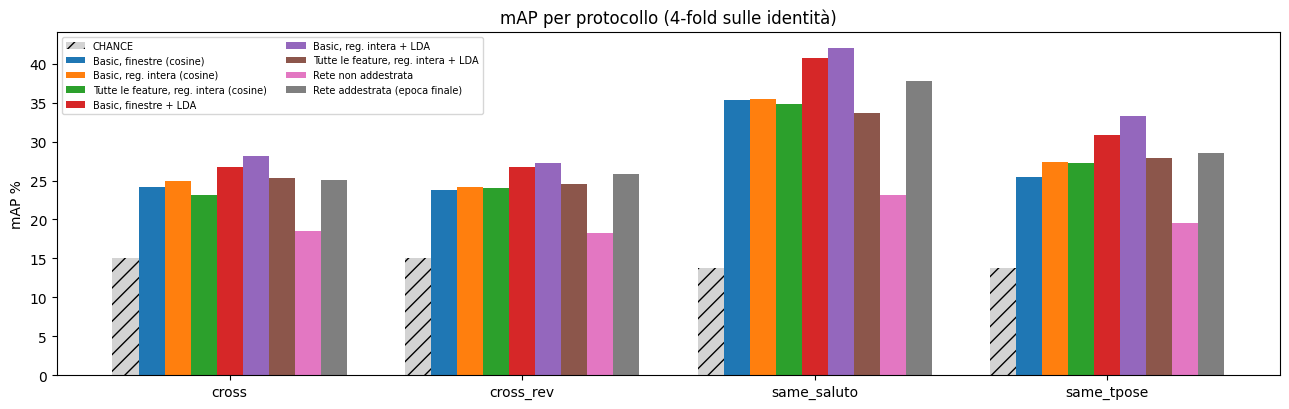

In [7]:
def results_table(store):
    rows, rows_std = [], []
    ch = aggregate_folds(next(iter(store.values())))
    rows.append({'metodo': 'CHANCE', **{f'{k} {m}': ch[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'chance_rank1'), ('mAP', 'chance_mAP')]}})
    for name, res in store.items():
        a = aggregate_folds(res)
        rows.append({'metodo': name, **{f'{k} {m}': a[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'rank1'), ('mAP', 'mAP')]}})
        rows_std.append({'metodo': name, **{f'{k} {m}': a[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'rank1_std'), ('mAP', 'mAP_std')]}})
    return pd.DataFrame(rows).set_index('metodo').round(1), pd.DataFrame(rows_std).set_index('metodo').round(1)

table, table_std = results_table(store)
n_q = {k: sum(r[k]['n_queries'] for r in next(iter(store.values()))) for k in PROTOCOLS}
print('Query totali per protocollo (somma sui fold):', n_q)
print('\n=== RISULTATI (Rank-1 % / mAP %) ===');  display(table)
print('=== Deviazione standard tra fold ===');     display(table_std)

# --- grafico mAP per protocollo ---
fig, ax = plt.subplots(figsize=(13, 4.2))
names = list(table.index); xs = np.arange(len(PROTOCOLS)); width = 0.8 / len(names)
for i, nme in enumerate(names):
    vals = [table.loc[nme, f'{k} mAP'] for k in PROTOCOLS]
    ax.bar(xs + i * width, vals, width, label=nme, hatch='//' if nme == 'CHANCE' else None, color='lightgray' if nme == 'CHANCE' else None)
ax.set_xticks(xs + width * (len(names) - 1) / 2); ax.set_xticklabels(PROTOCOLS); ax.set_ylabel('mAP %')
ax.legend(fontsize=7, ncol=2); ax.set_title(f"mAP per protocollo ({CFG['n_folds']}-fold sulle identità)")
plt.tight_layout(); plt.show()

## 8. Come leggere i risultati

* **Ablazione:** il gruppo con la mAP più alta *da solo* e il calo quando lo togli da "tutte" mostrano dove sta l'informazione sull'identità (`static` = profilo statico, `spec`/`pc1`/`eig` = dinamica e struttura spaziale).
* **Finestre vs registrazione intera:** se la registrazione intera è migliore, le finestre da 100 pacchetti sono troppo corte.
* **Rete vs LDA:** con 33 identità di training la rete dovrebbe avvicinarsi alle feature handcrafted; se resta sotto, i dati sono ancora troppo pochi per una rete profonda.
* **Tutto vicino alla chance:** con ampiezza sola e queste registrazioni, l'informazione di identità è debole; prova `sanitization='raw'`/`'hampel'` e confronta, oppure aggiungi la fase.
* Confronta sempre con **CHANCE**: con 11 identità per fold la chance è più alta che con 22.
* Per più stabilità: `n_folds=11` (40 identità di training, 4 di test) oppure ripeti con altri `seed`.